<a href="https://colab.research.google.com/github/rlaj0730-design/deep-learning-study/blob/main/ex02__RNN_%ED%99%9C%EC%9A%A9%ED%95%98%EA%B8%B0(%EB%A6%AC%EB%B7%B0%EB%8D%B0%EC%9D%B4%ED%84%B0).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 구글 마운트
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 작업 경로 변경
%cd "/content/drive/MyDrive/Colab Notebooks/딥러닝응용"
# cd = change directory

/content/drive/MyDrive/Colab Notebooks/딥러닝응용


### 활용 데이터 : 영화 리뷰 데이터
- 목표 : 긍정/부정 리뷰 분류
- 시나리오
  - 월 사용자 200만 명을 보유한 영화 리뷰 플랫폼에 취업 성공 !!
  - 매일 평균 5000건 이상 리뷰가 등록됨 -> 직접 분류, 모니터링에는 한계
  - 실시간 감성 파악을 통해서 추천 알고리즘, 고객 대응, 마케팅 전략 등 즉시 반영해야하는 업무를 맡음

In [ ]:
# 파이썬 객체를 저장 가능한 형태로 바꿔서 파일로 저장
# 저장된 형태를 파이썬 객체로 바꿔주는 도구
import pickle

In [ ]:
with open('data/X_train_morphs.pkl', 'rb') as f : # '경로/파일명.확장자명', 'rb' : 읽기모드(read)
    X_train = pickle.load(f)

with open('data/X_test_morphs.pkl', 'rb') as f : # '경로/파일명.확장자명', 'rb' : 읽기모드(read)
    X_test = pickle.load(f)

with open('data/y_train_morphs.pkl', 'rb') as f : # '경로/파일명.확장자명', 'rb' : 읽기모드(read)
    y_train = pickle.load(f)

with open('data/y_test_morphs.pkl', 'rb') as f : # '경로/파일명.확장자명', 'rb' : 읽기모드(read)
    y_test = pickle.load(f)

In [ ]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((149995,), (49997,), (149995,), (49997,))

In [ ]:
# 토큰화, 수치화

In [ ]:
X_train[15]

'냥 매번 긴장 되다 재밌다'

In [ ]:
y_train[15] # 0 : 부정 / 1 : 긍정

np.int64(1)

In [ ]:
# 토큰화, 수치화
# 텍스트 데이터를 학습용 수치데이터로 변경하는 도구
from tensorflow.keras.layers import TextVectorization

# 공식문서
# https://www.tensorflow.org/api_docs/python/tf/keras/layers/TextVectorization?version=stable

In [ ]:
# 도구 객체 생성
vectorizer = TextVectorization(
    # 단어 사전으로 사용할 최대 단어수 설정
    max_tokens = 5000, # 최대 5000개의 단어를 사용해서 단어사전을 만들겠다

    # 텍스트를 어떻게 변환할지 지정
    output_mode = 'int', # 기본값 'int'

    # 출력되는 정수 시퀀스의 길이 고정
    output_sequence_length = 10,
    # 텍스트가 짧으면 패딩 (0)을 추가, 길면 자름

    # 텍스트 데이터를 표준화하는 방식 지정
    standardize = 'lower_and_strip_punctuation' # 기본값 'lower_and_strip_punctuation'
    # 소문자로 변환, 구두점을 제거
)

In [ ]:
# 벡터화 진행
# 전처리, 토큰화, 단어사전 구축
vectorizer.adapt(X_train)

# 단어가 사전에 등록된 순서에 따라 매핑
# 각 단어에 고유한 정수 인덱스 할당

In [ ]:
# 단어사전 수 확인
vectorizer.vocabulary_size()

5000

In [ ]:
# 학습 데이터를 벡터화해서 정수 시퀀스(학습 가능한 데이터)로 변환
X_train_vec = vectorizer(X_train)

In [ ]:
X_train[0]

'더빙 진짜 짜증나다 목소리'

In [ ]:
vectorizer(X_train)[0]

# [341, 11, 162, 505, 0, 0, 0, 0, 0, 0] 길이 10의 시퀀스
# 더빙 : 341
# 진짜 : 11
# 짜증나다 : 162
# 목소리 : 505
# 단어 사전에 매핑된 정수(인덱스) 값, 길이가 부족해서 0으로 패딩 부여

<tf.Tensor: shape=(10,), dtype=int64, numpy=array([341,  11, 162, 505,   0,   0,   0,   0,   0,   0])>

In [ ]:
X_train[10]

'인피니트 짱 진짜'

In [ ]:
vectorizer(X_train)[10]

<tf.Tensor: shape=(10,), dtype=int64, numpy=array([4245,  248,   11,    0,    0,    0,    0,    0,    0,    0])>

In [ ]:
# test 데이터 벡터화
X_test_vec = vectorizer(X_test)
X_test_vec.shape

TensorShape([49997, 10])

In [ ]:
X_train_vec.shape

TensorShape([149995, 10])

In [ ]:
# 입력데이터의 모양을 3차원 형태로 변환이 필요
# 이유는? RNN은 3차원(배치 크기, 시퀀스 길이, 입력 특성 차원)의 형태를 기대함
# (149995, 10, 1) / (49997, 10, 1)


In [ ]:
import numpy as np

In [ ]:
# 차원 확장 넘파이 함수
X_train_vec = np.expand_dims(X_train_vec, -1) # -1 : 마지막 축에 새로운 차원을 추가
X_test_vec = np.expand_dims(X_test_vec, -1)

In [ ]:
# 최종 모양 확인
X_train_vec.shape, X_test_vec.shape

((149995, 10, 1), (49997, 10, 1))

In [ ]:
# RNN 모델링

# 필요한 도구 불러오기
# 뼈대
from tensorflow.keras import Sequential

# 입력층, RNN층, 출력층
from tensorflow.keras.layers import InputLayer, SimpleRNN, Dense

In [ ]:
# 모델링
# 뼈대 구축
model = Sequential()
# 입력층 설계 shape -> RNN이 기대하는 데이터 3차원, shape 2차원(배치 크기는 빼고)
model.add(InputLayer(shape = (10,1)))
# 중간층 SimpleRNN, 뉴런 수 64
model.add(SimpleRNN(units = 64))
# 출력층 - 우리의 목표가 뭐더라? -> 유닛 수는 어떻게? 활성화함수는 어떻게?
model.add(Dense(units = 1, activation = 'sigmoid'))

# 출력층에서의 분류 / 회귀의 유닛 수, 활성화 함수
# 이진분류 : units = 1, activation = 'sigmoid'
# 다중분류 : units = 클래스 개수, activation = 'softmax'
# 회귀 : units = 1, activation = 'linear'

In [ ]:
# 학습 방법 및 평가 방법 설정
# 최적화함수 adam, 손실함수, 평가지표(정확도)
model.compile(loss = 'binary_crossentropy',
              optimizer = 'adam',
              metrics = ['accuracy']
              )

In [ ]:
# 모델 학습
# 벡터화된 문제데이터
# 답 데이터
# 학습 횟수 20
# 검증 비율 0.2
history = model.fit(
    X_train_vec,
    y_train,
    epochs=20,
    validation_split=0.2
)

Epoch 1/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 21s 5ms/step - accuracy: 0.5241 - loss: 0.6919 - val_accuracy: 0.5222 - val_loss: 0.6896
Epoch 2/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/step - accuracy: 0.5304 - loss: 0.6852 - val_accuracy: 0.5347 - val_loss: 0.6836
Epoch 3/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.5356 - loss: 0.6811 - val_accuracy: 0.5385 - val_loss: 0.6771
Epoch 4/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.5372 - loss: 0.6784 - val_accuracy: 0.5343 - val_loss: 0.6771
Epoch 5/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.5389 - loss: 0.6768 - val_accuracy: 0.5362 - val_loss: 0.6783
Epoch 6/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.5409 - loss: 0.6749 - val_accuracy: 0.5442 - val_loss: 0.6729
Epoch 7/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.5413 - loss: 0.6740 - val_accuracy: 0.5417 - val_loss: 0.6722
Epoch 8/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.5447 - loss: 0

In [ ]:
import matplotlib.pyplot as plt

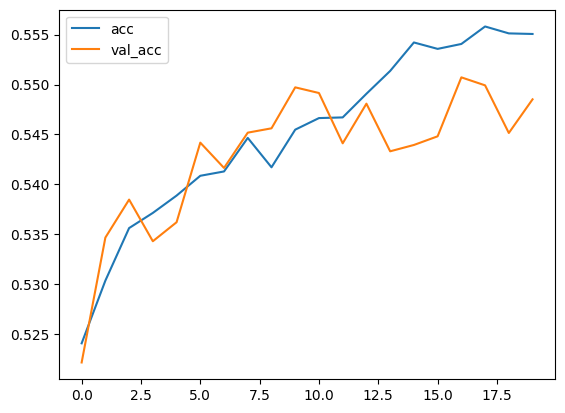

In [ ]:
# 학습 결과 시각화
# 정확도 0.5

plt.plot(model.history.history['accuracy'], label = 'acc')
plt.plot(model.history.history['val_accuracy'], label = 'val_acc')
plt.legend() # 범례 표시
plt.show()


In [ ]:
### 그래프 해석
- 정확도가 향상되며 학습이 진행되고는 있지만, 정확도가 높은 편은 아님
- 이유 : 가장 기본적인 RNN 모델 활용(SimpleRNN)

### 모델 성능(정확도)을 높이는 방법
- 더 좋은 성능의 모델 사용
- 데이터의 양, 질을 향상
- units 수 조정
- epochs 조정 등

In [ ]:
### SimpleRNN의 경우 긴 시퀀스를 가지는 데이터를 효과적으로 학습하기 어려움
- 순환 횟수가 길어질 수록 초반에 입력된 단어의 기억이 소실되는 기울기 소실 현상이 발생

### 이를 보완하기 위해 나온 모델(알고리즘) : LSTM(Long Short Term Memory)
- 장기기억, 단기기억 관리 계산이 추가된 모델

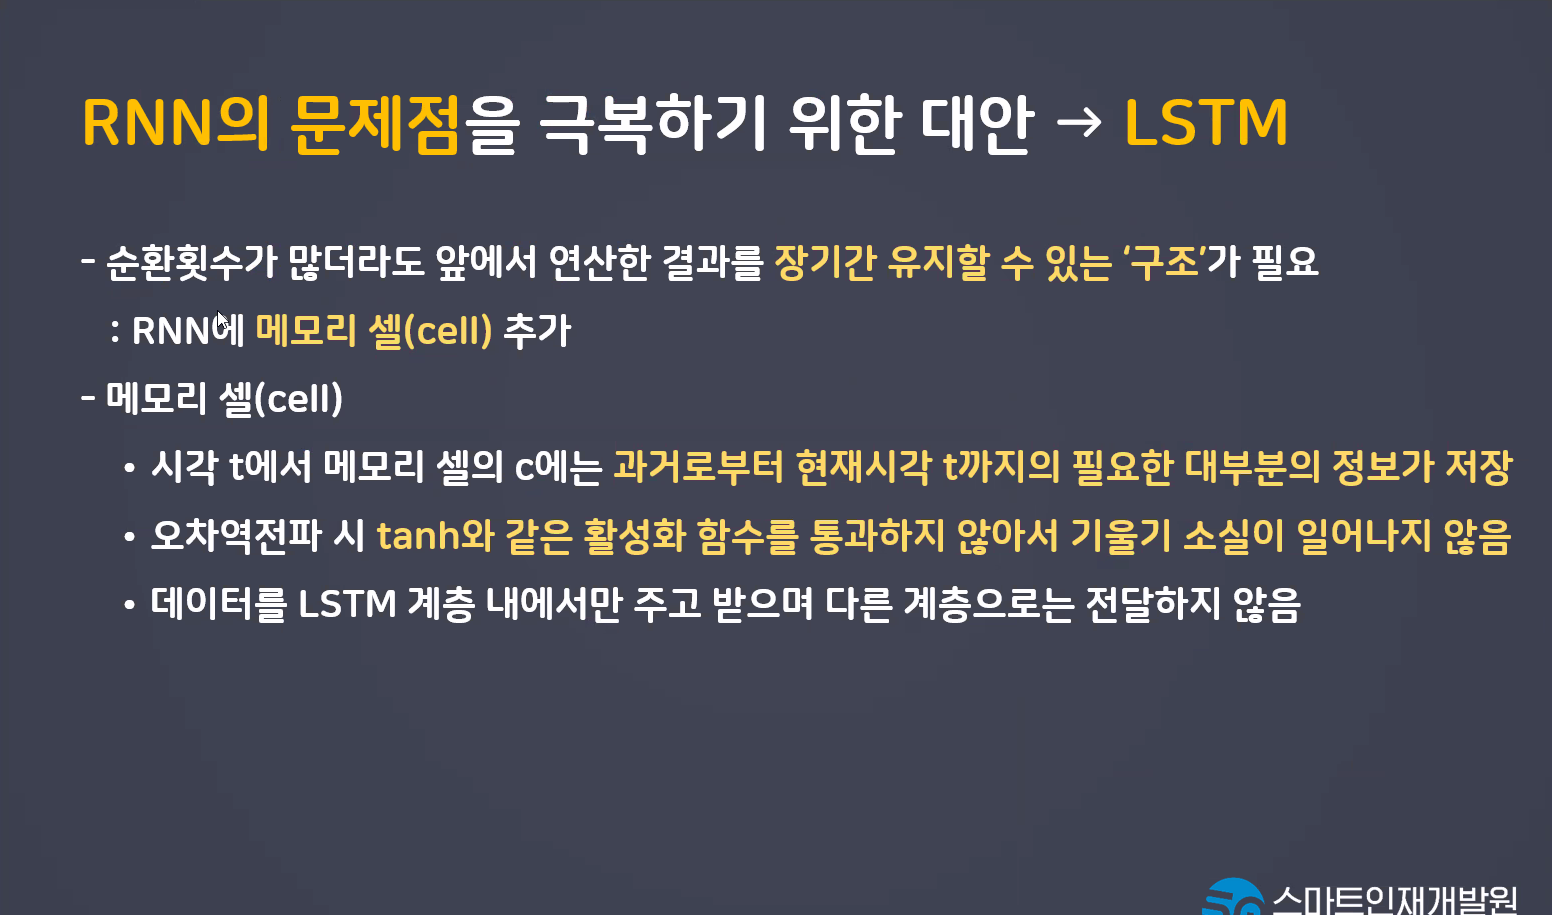

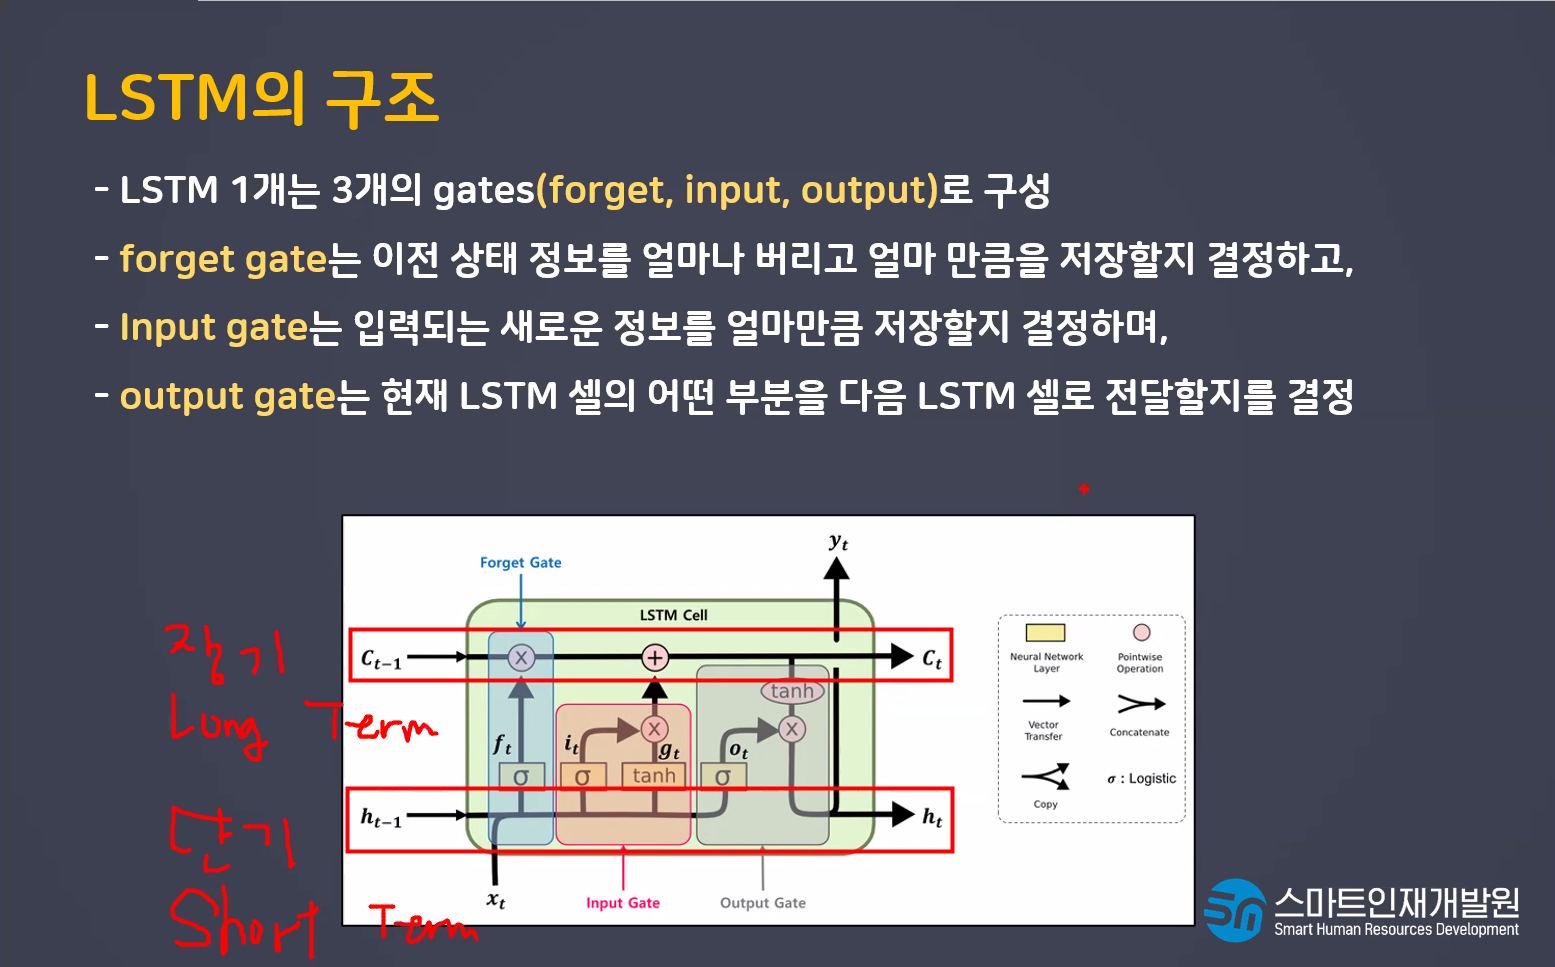

- 장기기억, 단기기억 관리 계산이 추가된 모델

In [ ]:
# c : 메모리 셀(cell) -> 순환 횟수가 많더라도 앞에서 연산한 결과를 기억할 수 있는 장기기억
# forget gate : 이전 정보를 얼마나 버리고 얼마만큼 저장할지 결정
# input gate : 입력되는 새로운 정보를 얼마만큼 저장할지 결정
# output gate : 현재 LSTM의 셀의 어떤 부분을 다음 LSTM 셀로 전달할지 결정

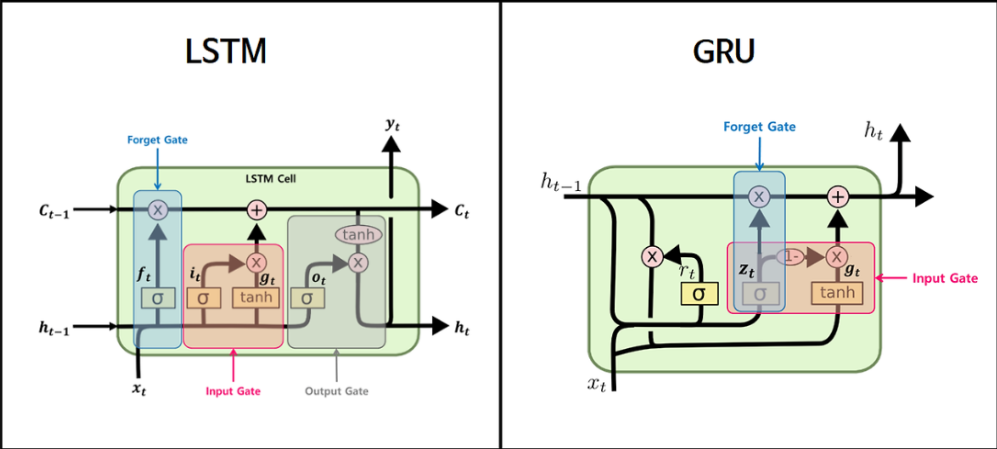

In [ ]:
# LSTM
# 장기 의존성을 처리할 수 있는 RNN 계열의 한 종류
# 기울기 소실 문제를 해결하기 위해서 셀, 3개의 게이트를 사용해서 정보를 선택적으로 기억하거나 잊음
# 긴 시퀀스 데이터를 처리할 때 유리함
# 텍스트 생성, 번역, 시계열 데이터 예측 등 자주 사용 됨
# 연산이 복잡해서 학습이 조금 오래 걸리는 편

# GRU(Gated Recurrent Unit)
# LSTM보다 간단한 구조의 RNN 계열의 한 종류
# LSTM의 모든 기능을 포합하면서도 좀 더 가볍고 빠름
# 셀 상태 대신 은닉 상태(hidden state)만 사용, 2개의 게이트(reset gate, update gate)를 통해 정보를 관리
# 간단한 구조 덕분에 학습 속도가 빠른 편, 성능도 LSTM과 비슷한 경우가 많음

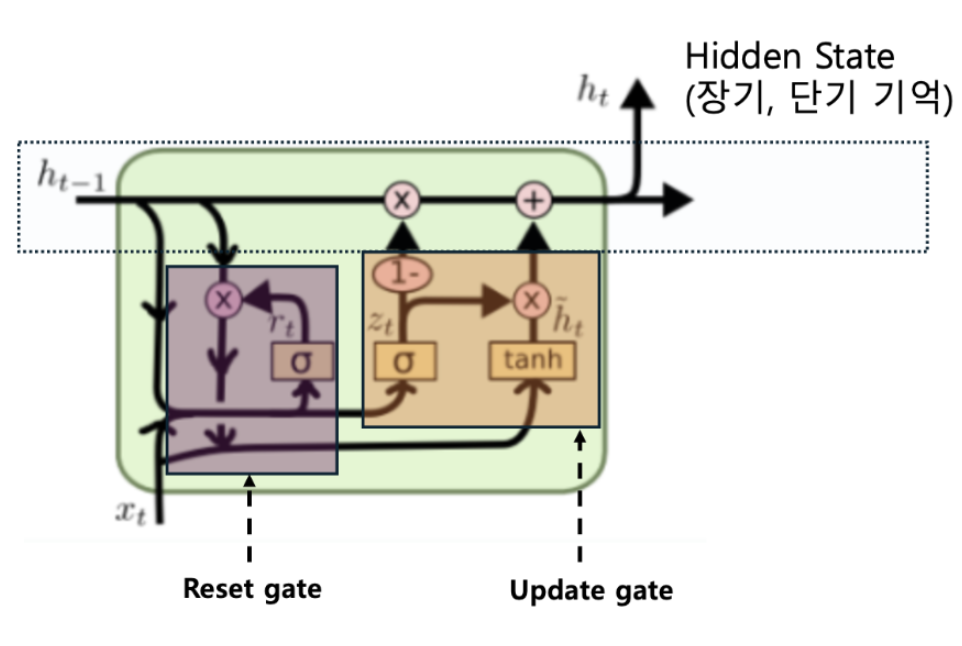

In [ ]:
# LSTM, GRU 불러오기
from tensorflow.keras.layers import LSTM, GRU

In [ ]:
# 모델링
# 변수 한번에 지정하기 ctrl + shift + L
lstm_model = Sequential()

lstm_model.add(InputLayer(shape = (10,1)))

lstm_model.add(LSTM(units = 64))

lstm_model.add(Dense(units = 1, activation = 'sigmoid'))

# 학습 방법 및 평가 방법 설정

lstm_model.compile(loss = 'binary_crossentropy',
              optimizer = 'adam',
              metrics = ['accuracy']
              )

# 모델 학습
lstm_model.fit(
    X_train_vec,
    y_train,
    epochs=20,
    validation_split=0.2
)

Epoch 1/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 34s 9ms/step - accuracy: 0.5547 - loss: 0.6810 - val_accuracy: 0.5516 - val_loss: 0.6805
Epoch 2/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 31s 8ms/step - accuracy: 0.5641 - loss: 0.6749 - val_accuracy: 0.5608 - val_loss: 0.6759
Epoch 3/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 31s 8ms/step - accuracy: 0.5690 - loss: 0.6695 - val_accuracy: 0.5672 - val_loss: 0.6687
Epoch 4/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 41s 8ms/step - accuracy: 0.5745 - loss: 0.6650 - val_accuracy: 0.5788 - val_loss: 0.6634
Epoch 5/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 31s 8ms/step - accuracy: 0.5772 - loss: 0.6608 - val_accuracy: 0.5788 - val_loss: 0.6621
Epoch 6/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 40s 8ms/step - accuracy: 0.5836 - loss: 0.6574 - val_accuracy: 0.5757 - val_loss: 0.6595
Epoch 7/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 37s 10ms/step - accuracy: 0.5853 - loss: 0.6552 - val_accuracy: 0.5793 - val_loss: 0.6620
Epoch 8/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - accuracy: 0.5902 - loss: 

In [ ]:
# 모델링

gru_model = Sequential()

gru_model.add(InputLayer(shape = (10,1)))

gru_model.add(GRU(units = 64))

gru_model.add(Dense(units = 1, activation = 'sigmoid'))

# 학습 방법 및 평가 방법 설정

gru_model.compile(loss = 'binary_crossentropy',
              optimizer = 'adam',
              metrics = ['accuracy']

              )

# 모델 학습
gru_model.fit(
    X_train_vec,
    y_train,
    epochs=20,
    validation_split=0.2
)

Epoch 1/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 40s 10ms/step - accuracy: 0.5538 - loss: 0.6819 - val_accuracy: 0.5624 - val_loss: 0.6772
Epoch 2/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 37s 10ms/step - accuracy: 0.5669 - loss: 0.6726 - val_accuracy: 0.5587 - val_loss: 0.6745
Epoch 3/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 36s 10ms/step - accuracy: 0.5736 - loss: 0.6680 - val_accuracy: 0.5609 - val_loss: 0.6717
Epoch 4/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - accuracy: 0.5760 - loss: 0.6650 - val_accuracy: 0.5746 - val_loss: 0.6661
Epoch 5/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 35s 9ms/step - accuracy: 0.5809 - loss: 0.6612 - val_accuracy: 0.5768 - val_loss: 0.6625
Epoch 6/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - accuracy: 0.5865 - loss: 0.6569 - val_accuracy: 0.5840 - val_loss: 0.6635
Epoch 7/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 35s 9ms/step - accuracy: 0.5880 - loss: 0.6542 - val_accuracy: 0.5832 - val_loss: 0.6572
Epoch 8/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 45s 10ms/step - accuracy: 0.5928 - lo

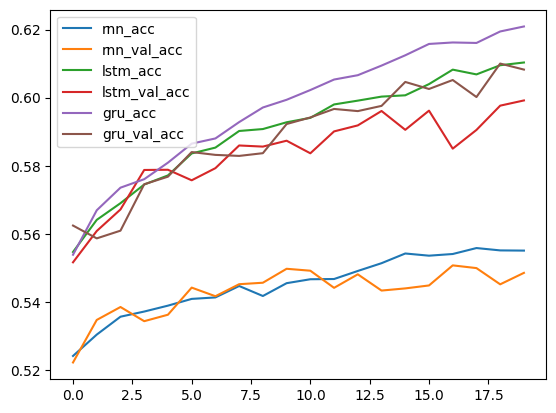

In [ ]:
# 3개 모델 비교 시각화# 3개 모델 비교 시각화

plt.plot(model.history.history['accuracy'], label = 'rnn_acc')
plt.plot(model.history.history['val_accuracy'], label = 'rnn_val_acc')

plt.plot(lstm_model.history.history['accuracy'], label = 'lstm_acc')
plt.plot(lstm_model.history.history['val_accuracy'], label = 'lstm_val_acc')

plt.plot(gru_model.history.history['accuracy'], label = 'gru_acc')
plt.plot(gru_model.history.history['val_accuracy'], label = 'gru_val_acc')

plt.legend() # 범례 표시
plt.show()

### 워드임베딩
- 텍스트마이닝, 자연어처리 모델링을 할 때 입력되는 데이터의 수치화 방법 중 하나
- 단어의 본질적인 의미를 파악할 수 있도록 수치화를 비교적 정교하게 진행
- 희소 표현(원핫인코딩)에서 밀집 표현(실수 형태)로 변환

### word2vec 맛보기
- 임베딩 벡터 중심으로 간단하게만 진행

In [ ]:
!pip install gensim

# gensim : 텍스트마이닝, 자연어처리 분야에 유용한 패키지

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 59.4 MB/s  0:00:00


In [ ]:
# word2vec 모델(사전학습모델)을 활용한 임베딩

import gensim.downloader as api

# 복잡하게 설치할 필요 없이 간단하게 호출해서 사전학습된 워드임베딩 모델 불러오기

In [ ]:
# api.info() : 모델들 정보 출력(결과값 : 딕셔너리 타입)
api.info()

{'corpora': {'semeval-2016-2017-task3-subtaskBC': {'num_records': -1,
   'record_format': 'dict',
   'file_size': 6344358,
   'reader_code': 'https://github.com/RaRe-Technologies/gensim-data/releases/download/semeval-2016-2017-task3-subtaskB-eng/__init__.py',
   'license': 'All files released for the task are free for general research use',
   'fields': {'2016-train': ['...'],
    '2016-dev': ['...'],
    '2017-test': ['...'],
    '2016-test': ['...']},
   'description': 'SemEval 2016 / 2017 Task 3 Subtask B and C datasets contain train+development (317 original questions, 3,169 related questions, and 31,690 comments), and test datasets in English. The description of the tasks and the collected data is given in sections 3 and 4.1 of the task paper http://alt.qcri.org/semeval2016/task3/data/uploads/semeval2016-task3-report.pdf linked in section “Papers” of https://github.com/RaRe-Technologies/gensim-data/issues/18.',
   'checksum': '701ea67acd82e75f95e1d8e62fb0ad29',
   'file_name': 'se

In [ ]:
api.info()['models'] # 여러 정보들 중에서 models 키 접근
# 결과값 : 딕셔너리 타입

{'fasttext-wiki-news-subwords-300': {'num_records': 999999,
  'file_size': 1005007116,
  'base_dataset': 'Wikipedia 2017, UMBC webbase corpus and statmt.org news dataset (16B tokens)',
  'reader_code': 'https://github.com/RaRe-Technologies/gensim-data/releases/download/fasttext-wiki-news-subwords-300/__init__.py',
  'license': 'https://creativecommons.org/licenses/by-sa/3.0/',
  'parameters': {'dimension': 300},
  'description': '1 million word vectors trained on Wikipedia 2017, UMBC webbase corpus and statmt.org news dataset (16B tokens).',
  'read_more': ['https://fasttext.cc/docs/en/english-vectors.html',
   'https://arxiv.org/abs/1712.09405',
   'https://arxiv.org/abs/1607.01759'],
  'checksum': 'de2bb3a20c46ce65c9c131e1ad9a77af',
  'file_name': 'fasttext-wiki-news-subwords-300.gz',
  'parts': 1},
 'conceptnet-numberbatch-17-06-300': {'num_records': 1917247,
  'file_size': 1225497562,
  'base_dataset': 'ConceptNet, word2vec, GloVe, and OpenSubtitles 2016',
  'reader_code': 'https:/

In [ ]:
# 딕셔너리 함수 -> 키 값만 확인하는 함수
api.info()['models'].keys()

# 임베딩 모델 이름 확인

dict_keys(['fasttext-wiki-news-subwords-300', 'conceptnet-numberbatch-17-06-300', 'word2vec-ruscorpora-300', 'word2vec-google-news-300', 'glove-wiki-gigaword-50', 'glove-wiki-gigaword-100', 'glove-wiki-gigaword-200', 'glove-wiki-gigaword-300', 'glove-twitter-25', 'glove-twitter-50', 'glove-twitter-100', 'glove-twitter-200', '__testing_word2vec-matrix-synopsis'])

In [ ]:
# 딕셔너리 함수 -> value값 확인하는 함수
api.info()['models'].values()

# 임베딩 모델 이름 확인

dict_values([{'num_records': 999999, 'file_size': 1005007116, 'base_dataset': 'Wikipedia 2017, UMBC webbase corpus and statmt.org news dataset (16B tokens)', 'reader_code': 'https://github.com/RaRe-Technologies/gensim-data/releases/download/fasttext-wiki-news-subwords-300/__init__.py', 'license': 'https://creativecommons.org/licenses/by-sa/3.0/', 'parameters': {'dimension': 300}, 'description': '1 million word vectors trained on Wikipedia 2017, UMBC webbase corpus and statmt.org news dataset (16B tokens).', 'read_more': ['https://fasttext.cc/docs/en/english-vectors.html', 'https://arxiv.org/abs/1712.09405', 'https://arxiv.org/abs/1607.01759'], 'checksum': 'de2bb3a20c46ce65c9c131e1ad9a77af', 'file_name': 'fasttext-wiki-news-subwords-300.gz', 'parts': 1}, {'num_records': 1917247, 'file_size': 1225497562, 'base_dataset': 'ConceptNet, word2vec, GloVe, and OpenSubtitles 2016', 'reader_code': 'https://github.com/RaRe-Technologies/gensim-data/releases/download/conceptnet-numberbatch-17-06-300

In [ ]:
# 딕셔너리 함수 -> key, value값 확인하는 함수
api.info()['models'].items()

dict_items([('fasttext-wiki-news-subwords-300', {'num_records': 999999, 'file_size': 1005007116, 'base_dataset': 'Wikipedia 2017, UMBC webbase corpus and statmt.org news dataset (16B tokens)', 'reader_code': 'https://github.com/RaRe-Technologies/gensim-data/releases/download/fasttext-wiki-news-subwords-300/__init__.py', 'license': 'https://creativecommons.org/licenses/by-sa/3.0/', 'parameters': {'dimension': 300}, 'description': '1 million word vectors trained on Wikipedia 2017, UMBC webbase corpus and statmt.org news dataset (16B tokens).', 'read_more': ['https://fasttext.cc/docs/en/english-vectors.html', 'https://arxiv.org/abs/1712.09405', 'https://arxiv.org/abs/1607.01759'], 'checksum': 'de2bb3a20c46ce65c9c131e1ad9a77af', 'file_name': 'fasttext-wiki-news-subwords-300.gz', 'parts': 1}), ('conceptnet-numberbatch-17-06-300', {'num_records': 1917247, 'file_size': 1225497562, 'base_dataset': 'ConceptNet, word2vec, GloVe, and OpenSubtitles 2016', 'reader_code': 'https://github.com/RaRe-Te

In [ ]:
# 사용 가능한 여러 모델 리스트업
for model_name, model_data in sorted(api.info()['models'].items()):

    # 각 모델 데이터에서 'num_records' 키에 해당하는 값이 있으면 사용, 없으면 기본값 -1을 사용
    num_records = model_data.get('num_records', -1)

    # 각 모델의 설명을 40자 까지만 잘라서 표시하고 그 뒤에 '...'을 추가
    # ex> 이 모델은 어쩌고저쩌고 ...
    description = model_data['description'][:40] + '...'

    # 각 모델 이름, 레코드 수, 잘린 설명 출력
    # 레코드 수 : 데이터의 개수(각 레코드는 임베딩된 단어 하나를 의미)
    print(f"{model_name} ({num_records} records): {description}")

__testing_word2vec-matrix-synopsis (-1 records): [THIS IS ONLY FOR TESTING] Word vecrors ...
conceptnet-numberbatch-17-06-300 (1917247 records): ConceptNet Numberbatch consists of state...
fasttext-wiki-news-subwords-300 (999999 records): 1 million word vectors trained on Wikipe...
glove-twitter-100 (1193514 records): Pre-trained vectors based on  2B tweets,...
glove-twitter-200 (1193514 records): Pre-trained vectors based on 2B tweets, ...
glove-twitter-25 (1193514 records): Pre-trained vectors based on 2B tweets, ...
glove-twitter-50 (1193514 records): Pre-trained vectors based on 2B tweets, ...
glove-wiki-gigaword-100 (400000 records): Pre-trained vectors based on Wikipedia 2...
glove-wiki-gigaword-200 (400000 records): Pre-trained vectors based on Wikipedia 2...
glove-wiki-gigaword-300 (400000 records): Pre-trained vectors based on Wikipedia 2...
glove-wiki-gigaword-50 (400000 records): Pre-trained vectors based on Wikipedia 2...
word2vec-google-news-300 (3000000 records): Pre-trai

- Records : 레코드의 수, 즉 데이터의 개수를 의미(각 "레코드"는 임베딩된 단어 하나를 의미)

| 모델 이름                           | 레코드 수      | 설명                                                                                                  |
|-------------------------------------|----------------|-------------------------------------------------------------------------------------------------------|
| conceptnet-numberbatch-17-06-300    | 1,917,247      | ConceptNet Numberbatch는 개념 간의 관계를 학습한 모델.                                                 |
|                                     |                | 상식을 이해하고 개념 간 관계를 연결시키기 위해 개발됨.                                                 |
|                                     |                | 주로 의미 네트워크 연구에 사용됨. "고양이"와 "동물" 간의 관계를 학습.                                  |
| fasttext-wiki-news-subwords-300     | 999,999        | fastText는 단어뿐만 아니라 서브워드(단어의 작은 부분)를 학습.                                          |
|                                     |                | "unbelievable"을 "un", "believe", "able"로 나누어 학습.                                                 |
|                                     |                | Wikipedia와 뉴스 기사 데이터를 기반으로 학습됨.                                                       |
| glove-twitter-100                   | 1,193,514      | GloVe는 Stanford에서 개발된 모델로, 단어 간의 공간적 관계를 벡터로 표현.                               |
|                                     |                | 트위터 데이터(2억 개 트윗)로 학습되어 소셜 미디어 자연어 처리 작업에 적합.                             |
| word2vec-google-news-300            | 3,000,000      | Word2Vec은 구글 뉴스 데이터로 학습된 모델.                                                             |
|                                     |                | 뉴스 기사의 단어 간 유사성 및 의미적 관계를 잘 포착.                                                   |
|                                     |                | 뉴스 데이터 기반이기 때문에 자연어 처리에 많이 사용됨.                                                 |
| word2vec-ruscorpora-300             | 184,973        | Word2Vec ruscorpora는 러시아어 텍스트 기반의 모델로,                                                   |
|                                     |                | 러시아어 자연어 처리 작업에 사용됨.                                                                   |


In [ ]:
# word2vec-google-news-300 불러오기

# 3백만 개의 단어 벡터를 포함
# 각 단어는 300차원의 벡터로 표현

model = api.load('word2vec-google-news-300')

[==================================================] 100.0% 1662.8/1662.8MB downloaded


In [ ]:
# 'cat'이라는 단어에 대응하는 300차원의 벡터 출력
model['cat']

array([ 0.0123291 ,  0.20410156, -0.28515625,  0.21679688,  0.11816406,
        0.08300781,  0.04980469, -0.00952148,  0.22070312, -0.12597656,
        0.08056641, -0.5859375 , -0.00445557, -0.296875  , -0.01312256,
       -0.08349609,  0.05053711,  0.15136719, -0.44921875, -0.0135498 ,
        0.21484375, -0.14746094,  0.22460938, -0.125     , -0.09716797,
        0.24902344, -0.2890625 ,  0.36523438,  0.41210938, -0.0859375 ,
       -0.07861328, -0.19726562, -0.09082031, -0.14160156, -0.10253906,
        0.13085938, -0.00346375,  0.07226562,  0.04418945,  0.34570312,
        0.07470703, -0.11230469,  0.06738281,  0.11230469,  0.01977539,
       -0.12353516,  0.20996094, -0.07226562, -0.02783203,  0.05541992,
       -0.33398438,  0.08544922,  0.34375   ,  0.13964844,  0.04931641,
       -0.13476562,  0.16308594, -0.37304688,  0.39648438,  0.10693359,
        0.22167969,  0.21289062, -0.08984375,  0.20703125,  0.08935547,
       -0.08251953,  0.05957031,  0.10205078, -0.19238281, -0.09

In [ ]:
# 'cat'이랑 유사한 단어 나열
model.most_similar('cat')

[('cats', 0.8099379539489746),
 ('dog', 0.760945737361908),
 ('kitten', 0.7464985251426697),
 ('feline', 0.7326234579086304),
 ('beagle', 0.7150582671165466),
 ('puppy', 0.7075453400611877),
 ('pup', 0.6934291124343872),
 ('pet', 0.6891531348228455),
 ('felines', 0.6755931973457336),
 ('chihuahua', 0.6709762215614319)]

In [ ]:
# 유사한 단어 나열
model.most_similar('dog')

# 유사도를 계산해서 주어진 단어랑 벡터 공간 상에서 가장 가까운 단어들을 나열
# 기본적으로는 코사인 유사도 점수 반환(-1 ~ 1 사이의 값)
# 벡터가 동일한 방향일 수록 1에 가까워지고, 반대 방향일수록 -1에 가까워짐

[('dogs', 0.8680489659309387),
 ('puppy', 0.8106428384780884),
 ('pit_bull', 0.780396044254303),
 ('pooch', 0.7627376914024353),
 ('cat', 0.7609457969665527),
 ('golden_retriever', 0.7500901818275452),
 ('German_shepherd', 0.7465174198150635),
 ('Rottweiler', 0.7437615394592285),
 ('beagle', 0.7418621778488159),
 ('pup', 0.740691065788269)]

In [ ]:
# 벡터간 유사성 계산
# most_similar_cosmul() : 코사인 유사도를 기반으로 cosmul 방식을 사용
# 두 벡터 사이의 유사성을 계산하는 함수

# 'father' + 'woman' - 'man'
# 단어 벡터 더하기 positive 리스트
# 단어 벡터 빼기 negative 리스트

model.most_similar_cosmul(positive = ['father', 'woman'], negative = ['man'])

[('mother', 1.025557279586792),
 ('daughter', 0.991381824016571),
 ('husband', 0.9660825729370117),
 ('eldest_daughter', 0.9520994424819946),
 ('sister', 0.9376709461212158),
 ('niece', 0.936501145362854),
 ('aunt', 0.9253349304199219),
 ('son', 0.9216511249542236),
 ('daughters', 0.9201593995094299),
 ('grandmother', 0.9164769649505615)]

In [ ]:
# king + woman - man
model.most_similar_cosmul(positive = ['emperor', 'woman'], negative = ['man'])

[('empress', 0.9139878153800964),
 ('emperors', 0.8525159955024719),
 ('empresses', 0.8506539463996887),
 ('imperial_throne', 0.8408592939376831),
 ('Queen_Consort', 0.8395031094551086),
 ('Emperor', 0.8371301293373108),
 ('Imperial_Household', 0.8336353898048401),
 ('Wu_Zetian', 0.8334375023841858),
 ('Empress_Dowager_Cixi', 0.8318643569946289),
 ('Empress', 0.8286706209182739)]

In [ ]:
# 데이터 불러오기 및 벡터화
import pickle

with open('data/X_train_morphs.pkl', 'rb') as f : # '경로/파일명.확장자명', 'rb' : 읽기모드
    X_train = pickle.load(f)

with open('data/X_test_morphs.pkl', 'rb') as f : # '경로/파일명.확장자명', 'rb' : 읽기모드
    X_test = pickle.load(f)

with open('data/y_train_morphs.pkl', 'rb') as f : # '경로/파일명.확장자명', 'rb' : 읽기모드
    y_train = pickle.load(f)

with open('data/y_test_morphs.pkl', 'rb') as f : # '경로/파일명.확장자명', 'rb' : 읽기모드
    y_test = pickle.load(f)

# 텍스트 데이터를 학습용 수치데이터로 변경(토큰화, 수치화 등)하는 도구
from tensorflow.keras.layers import TextVectorization

# 벡터화 도구 객체 생성
vetorizer = TextVectorization(
    max_tokens = 5000, # 사용할 최대 단어 토큰수 제한
    # 최대 5000개의 단어를 사용해서 단어 사전을 만들겠다

    output_mode = 'int', # 빈도 기반으로 랭킹화하기 위해서 숫자로 지정
    # 텍스트를 어떻게 변환할지 지정하는 옵션

    output_sequence_length = 10, # 출력되는 정수 시퀀스의 길이 고정
    # 텍스트가 짧으면 패딩(0)을 추가하고, 길면 자름

    standardize = 'lower_and_strip_punctuation'
    # standardize : 텍스트 데이터를 표준화하는 방식 지정(텍스트를 일관된 형식으로 정리)
    # 'lower_and_strip_punctuation' : 텍스트에서 모든 문자를 소문자로 변환하고, 구두점을 제거
)

# 훈련데이터 기반으로 전처리 토큰화 단어사전 구축
vetorizer.adapt(X_train)

X_train_vec = vetorizer(X_train)
X_test_vec = vetorizer(X_test)

In [ ]:
# 사전학습된 임베딩 모델을 가져다 쓸 수도 있지만
# 우리 모델과 결합된 상태로 직접 학습시킬 수도 있음!

In [ ]:
# 임베딩 층(layer) 쌓는 도구 불러오기
from tensorflow.keras.layers import Embedding

In [ ]:
# LSTM 모델에 워드임베딩을 조합해서 모델링
# 모델링에 필요한 도구
from tensorflow.keras import Sequential
from tensorflow.keras.layers import InputLayer, Dense, LSTM

In [ ]:
# 모델링

embedding_model = Sequential()

# 임베딩 레이어(층) 추가
embedding_model.add(Embedding(5000, 50)) # 사용하는 단어사전의 수, 벡터 차원 수
# 5000 : 사용할 수 있는 단어의 최대 수(우리가 사용하는 단어사전의 크기)
# 50 : 각 단어를 50차원의 벡터로 변환
# 즉, 50개의 실수로 이루어진 벡터로 표현
# LSTM으로 전달되는 형태는?
# (개수, 시퀀스 수(문장 길이), 차원 형태)
# 개수는 생략 / (10, 50)

embedding_model.add(LSTM(units = 64))

embedding_model.add(Dense(units = 1, activation = 'sigmoid'))

# 학습 방법 및 평가 방법 설정

embedding_model.compile(loss = 'binary_crossentropy',
              optimizer = 'adam',
              metrics = ['accuracy']

              )

# 모델 학습
embedding_model.fit(
    X_train_vec,
    y_train,
    epochs=20,
    validation_split=0.2
)

Epoch 1/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 51s 13ms/step - accuracy: 0.7949 - loss: 0.4309 - val_accuracy: 0.8117 - val_loss: 0.4052
Epoch 2/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 84s 13ms/step - accuracy: 0.8246 - loss: 0.3798 - val_accuracy: 0.8197 - val_loss: 0.3910
Epoch 3/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 81s 13ms/step - accuracy: 0.8385 - loss: 0.3524 - val_accuracy: 0.8205 - val_loss: 0.3937
Epoch 4/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 80s 13ms/step - accuracy: 0.8497 - loss: 0.3313 - val_accuracy: 0.8198 - val_loss: 0.4026
Epoch 5/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - accuracy: 0.8621 - loss: 0.3094 - val_accuracy: 0.8180 - val_loss: 0.4183
Epoch 6/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - accuracy: 0.8723 - loss: 0.2870 - val_accuracy: 0.8109 - val_loss: 0.4348
Epoch 7/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - accuracy: 0.8838 - loss: 0.2642 - val_accuracy: 0.8122 - val_loss: 0.4595
Epoch 8/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - accuracy: 0.8944 -

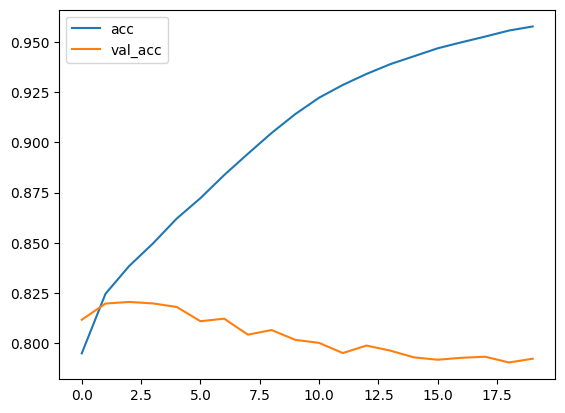

In [ ]:
# 학습 결과 시각화
import matplotlib.pyplot as plt

plt.plot(embedding_model.history.history['accuracy'], label = 'acc')
plt.plot(embedding_model.history.history['val_accuracy'], label = 'val_acc')

plt.legend()
plt.show()

In [ ]:
# 우선 성능은 훨씬 좋아짐! 하지만, 과대적합 발생!!!

# 과대적합 제어 방
# 학습 횟수 조정, 데이터 늘리기(가장 좋은 방법), 콜백함수 활용(earlystopping), 드랍아웃(층을 무작위로 비활성화)

### 임베딩 레이어를 활용한 전이학습
- 전이학습 : 사전학습된 모델을 가져와서 사용
- 잘 만들어진 임베딩 벡터를 전이학습에 활용할 수 있다
- 임베딩 벡터 : 임베딩 레이어에 들어있는 숫자 묶음
- ex> 우리 상황에서는 5000개의 단어를 50개 차원의 벡터로 만든 것

In [ ]:
embedding_model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 50)         │       250,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        29,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 838,517 (3.20 MB)

 Trainable params: 279,505 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 559,012 (2.13 MB)

In [ ]:
# 모델에서 임베딩 층 가져오기
em_layer = embedding_model.get_layer('embedding')

# 학습이 완료된 모델명. get_layer(레이어 이름)
# 가져오고 싶은 레이어의 이름을 불러서 사용 -> 전이학습

### RNN 계열 층 여러개 쌓기
- RNN 계열의 레이어는 기본적으로 다수 입력, 단일 출력 구조
  - ex> 리뷰데이터 -> 긍정/부정 분류
- RNN 계열의 레이어를 여러 개 쌓기 위해서는 이전 층을 다수 입력, 다수 출력 구조로 변경 -> RETURN_SEQUENCES 속성 활용

In [ ]:
# 모델링

embedding_model2 = Sequential()

# 임베딩 레이어(층) 추가
embedding_model2.add(em_layer) # 사전학습된 층 가져오기

embedding_model2.add(LSTM(64, return_sequences= True)) # 다수입력 다수출력 구조로 변경

# return_sequences= False (기본값)
# 다수입력 단일출력
# 최종 예측값만 필요할 때 (-> 감성 분석)

# return_sequences= True
# 다수입력 다수출력
# 모든 시점에 대한 정보를 다음 층에 넘길 때
# ex> RNN 계열 모델을 여러 층 쌓을 때
# 각 시점에 대한 모든 출력을 원할 때 (-> 번역 작업)

embedding_model2.add(LSTM(64))

embedding_model2.add(Dense(units = 1, activation = 'sigmoid'))

# 학습 방법 및 평가 방법 설정

embedding_model2.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

# 모델 학습
embedding_model2.fit(X_train_vec, y_train, epochs = 20, validation_split=0.2)

Epoch 1/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 79s 20ms/step - accuracy: 0.8660 - loss: 0.3046 - val_accuracy: 0.8068 - val_loss: 0.4790
Epoch 2/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 73s 19ms/step - accuracy: 0.9015 - loss: 0.2299 - val_accuracy: 0.8000 - val_loss: 0.5525
Epoch 3/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 75s 20ms/step - accuracy: 0.9189 - loss: 0.1890 - val_accuracy: 0.7988 - val_loss: 0.6331
Epoch 4/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 85s 21ms/step - accuracy: 0.9300 - loss: 0.1629 - val_accuracy: 0.7954 - val_loss: 0.6936
Epoch 5/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 74s 20ms/step - accuracy: 0.9365 - loss: 0.1459 - val_accuracy: 0.7949 - val_loss: 0.7892
Epoch 6/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 82s 20ms/step - accuracy: 0.9426 - loss: 0.1325 - val_accuracy: 0.7955 - val_loss: 0.9381
Epoch 7/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 75s 20ms/step - accuracy: 0.9465 - loss: 0.1217 - val_accuracy: 0.7937 - val_loss: 0.9508
Epoch 8/20
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 83s 20ms/step - accuracy: 0.9497 -

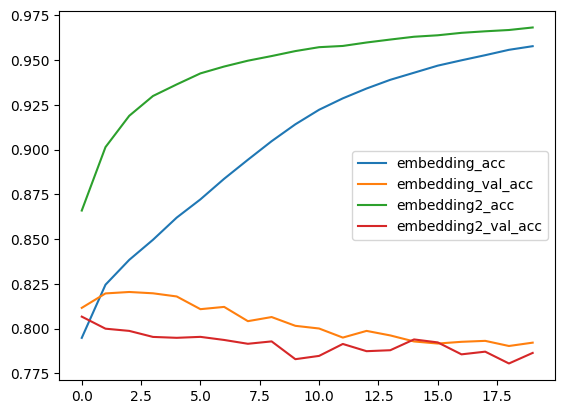

In [ ]:

plt.plot(history1['accuracy'], label='embedding_acc')
plt.plot(history1['val_accuracy'], label='embedding_val_acc')


plt.plot(embedding_model2.history.history['accuracy'], label='embedding2_acc')
plt.plot(embedding_model2.history.history['val_accuracy'], label='embedding2_val_acc')

plt.legend()
plt.show()